# Design Guide : Telescopic cascode in switch capacitor integrator 

## Telescopic cascode

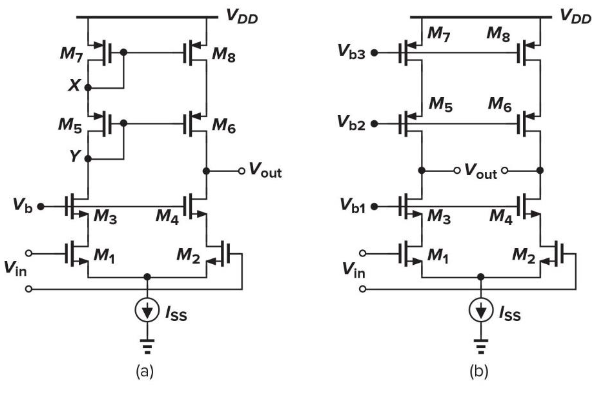 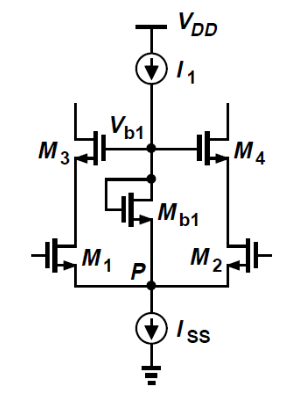

### Équation de départ
$$\frac{g_{m1}}{\frac{g_{ds1} \cdot g_{ds5}}{g_{m5}} + \frac{g_{ds3} \cdot g_{ds7}}{g_{m7}}}$$

### Équation en ratio de gm_gds et ratio gm_gm
$$\frac{1}{\frac{1}{\left(\frac{g_{m1}}{g_{ds1}}\right)\left(\frac{g_{m5}}{g_{ds5}}\right)} + \frac{g_{m3}}{g_{m1}} \cdot \frac{1}{\left(\frac{g_{m3}}{g_{ds3}}\right)\left(\frac{g_{m7}}{g_{ds7}}\right)}}$$

## Step 1 : import Libs

In [ ]:
import numpy as np
import scipy.constants as sc
import catppuccin
import matplotlib.pyplot as plt
from pygmid import Lookup as lk
pmos4 = lk('../../lookup_table/035/pmos4.mat')
nmos4 = lk('../../lookup_table/035/nmos4.mat')
import sys; sys.path.append('../..')
import adri
from scipy.interpolate import interp1d
def interp1(x, y, value):
    # Interpolation function
    # Perform cubic interpolation using interp1d
    f = interp1d(x, y, kind='cubic')
    return f(value)

## Step 2 : Specifications

In [ ]:
#Design Spec 
s = {
    'ts'        : 200e-9,
    'ed'        : 0.01/100,
    'fu1'       : 0,
    'vod_noise' : 100e-6*0.5,
    'FO'        : 4,
    'G'         : 1/4,
    'vod_final' : 0.2,
    'VDD' : 2.7,
    'VCM' : 1.25,
    'V_SWING_P2P_DIFF' : 0.5,
    'VS' : 0.6
}
beta_max = 1 / (1 + s['G'])
s['fu1'] = 1 / (2 * np.pi) * np.log(1 / s['ed']) / s['ts']

# Constants for another design
d = {
    'gamma': 0.9,
    'Lcas': 0,
    'gm_IDcas': 0,
    #'gm3_gm1':0.5,
    'L1' : 0,
    'cself': 0,
    'gm_ID1': 0,
    'beta': 0
}

## Step 3 : Set GM/ID given output swing

In [ ]:
VDD = s['VDD']
VCM = s['VCM']
V_SWING_P2P_DIFF = s['V_SWING_P2P_DIFF']
VOUT_CM_HIGH = VCM+V_SWING_P2P_DIFF/2
VOUT_CM_LOW = VCM-V_SWING_P2P_DIFF/2
VDS_MOS = VOUT_CM_LOW/3
VS = s['VS']
print('2 MOS pour', VOUT_CM_HIGH)
print('3 MOS pour', VOUT_CM_LOW)
gm_id = 2/(VDS_MOS)
print('VDS_MOS =  ', VDS_MOS)
print('gm_id > ', gm_id)
print('On prend gm_id = 12')


##On prend gm_id = 15
d['gm_IDcas'] = 12
d['gm_ID1'] = 20

2 MOS pour 1.5
3 MOS pour 1.0
VDS_MOS =   0.3333333333333333
gm_id >  6.0
On prend gm_id = 12


## Step 4 : Set L for Gain
### Estimation du gain, mais pour le gain précis en mode SC, il faudra calculer le beta
Si input MOS trop gros, le beta casse le gain


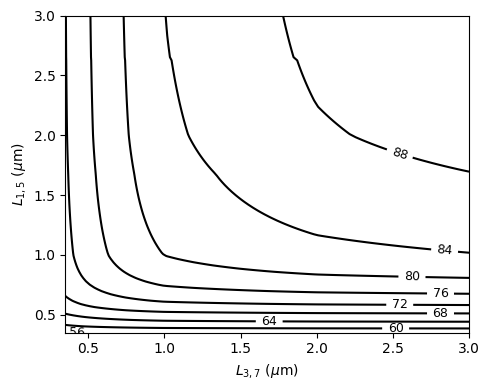

In [ ]:
#Set L sweep for plot 
L = np.linspace(0.35, 3, 100)
beta_max = 1 / (1 + s['G'])
beta = 3/4 * beta_max
kappa = 0.7
gm_id1 = 20
gm3_gm1 = 0.5
gm_id3 = gm_id1 * gm3_gm1

#Compute gain param
gm_gds1 = nmos4.lookup('GM_GDS', GM_ID = gm_id1, L = L, VDS = VDS_MOS, VSB = VS)
gm_gds5 = nmos4.lookup('GM_GDS', GM_ID = gm_id1, L = L, VDS = VCM-VDS_MOS-VS, VSB = VDS_MOS+VS)
gm_gds7 = pmos4.lookup('GM_GDS', GM_ID = gm_id3, L = L, VDS = VOUT_CM_HIGH/2, VSB = 0)
gm_gds3 = pmos4.lookup('GM_GDS', GM_ID = gm_id3, L = L, VDS = VOUT_CM_HIGH/2, VSB =  VOUT_CM_HIGH/2)

L0 = np.zeros((len(L), len(L)))
#Copute L0 for range of Lcascode
for i in range(len(L)):
    L0[i, :] =   1 / (    1/(gm_gds1*gm_gds5) + gm3_gm1*(1/(gm_gds3[i]*gm_gds7[i]))) * beta * kappa
L0 = 20*np.log10(L0)
# Plotting
fig, ax = plt.subplots(figsize=(5, 4))
C = ax.contour(L, L, L0, colors='k', levels=8)
ax.clabel(C, fmt='%d', fontsize=9)
ax.set_xlabel(r'$L_{3,7}$ ($\mu$m)')
ax.set_ylabel(r'$L_{1,5}$ ($\mu$m)')
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams.update({"axes.grid": True})
plt.tight_layout()
plt.show()



### Choose L : 

In [ ]:
d['L1'] = 0.5
d['Lcas'] = 1

## Step 4 : Sizing loop

### Full design with Self loading loop+Sizing W,L 

In [ ]:
d['gm_ID1'] = np.linspace(3, 27, 50)
d['beta'] = beta_max * np.linspace(0.2, 1, 50)

# d['L1'] = 0.5
# d['Lcas'] = 1
# d['gm_IDcas'] = 12
# d['gm_ID1'] = 20

#To overwrite all
# #Design Spec 
# s = {
#     'ts'        : 200e-9,
#     'ed'        : 0.01/100,
#     'fu1'       : 1/(2*np.pi) * np.log(1/ (0.1/100)) / 50e-9,
#     'vod_noise' : 100e-6*0.5,
#     'FO'        : 4,
#     'G'         : 1/4,
#     'vod_final' : 0.2,
#     'VDD' : 2.7,
#     'VCM' : 1.25,
#     'V_SWING_P2P_DIFF' : 0.5,
#     'VS' : 0.6
# }
# beta_max = 1 / (1 + s['G'])
# s['fu1'] = 1 / (2 * np.pi) * np.log(1 / s['ed']) / s['ts']

# # Constants for another design
# d = {
#     'gamma': 0.9,
#     'Lcas': 2,
#     'gm_IDcas': 15,
#     'L1' : 2,
#     'cself': 0,
#     'gm_ID1': np.linspace(5, 28, 100),
#     'beta': beta_max * np.linspace(0.2, 1, 100)
# }

# Self loading sweep
cself = np.zeros(10)
gm_ID1 = np.zeros_like(cself)
beta = np.zeros_like(cself)

for i in range(len(cself)):
    d['cself'] = cself[i]
    m1,m5,m7,m3,mosbias,p = adri.telesopic_cascode(nmos4, pmos4, s, d)
    m = np.argmin(m1['ID'])
    gm_ID1[i] = m1['GM_ID'][m]
    beta[i] = d['beta'][m]
    if i + 1 < len(cself):
        cself[i + 1] = p['cself'][m]
# Final sizing point
gm_ID1_opt = gm_ID1[-1]
beta_opt = beta[-1]

d['gm_ID1'] =  np.array([gm_ID1_opt])
d['beta'] =  np.array([beta_opt])
m1,m5,m7,m3,mosbias,p = adri.telesopic_cascode(nmos4, pmos4, s, d)
adri.print_design_summary(s,d,m1,m5,m7,m3,mosbias,p)

# plt.tight_layout()
# plt.show()

## Step 5 : data extract for cadence

In [ ]:
# Extraction pour les MOS (W est déjà en unité correcte)
mos_data = [('M1', m1), ('M5', m5), ('M7', m7), ('M3', m3), ('mosbias', mosbias)]

for name, mos in mos_data:
    w_val = mos['W'].flatten()[0]
    l_val = mos['L']
    print(f"{name}_W {w_val:.3f}u")
    print(f"{name}_L {l_val:.2f}u")

# Extraction pour les Capacités
# On multiplie par 1e15 pour passer des Farads aux femtofarads
caps = [('Cf', p['CF']), ('Cs', p['CS']), ('Cl', p['CL'])]

for name, val in caps:
    val_f = val.flatten()[0] * 1e15
    print(f"{name} {val_f:.1f}f")

# Extraction correcte de la valeur scalaire
valeur_ibias = m1['ID'].flatten()[0] *1e6
# Application du formatage avec 'f' (pour le suffixe)
print(f"ibias {valeur_ibias:.3f}u")

M1_W 44.188u
M1_L 0.50u
M5_W 84.868u
M5_L 1.00u
M7_W 21.240u
M7_L 1.00u
M3_W 21.240u
M3_L 1.00u
mosbias_W 0.433u
mosbias_L 7.00u
Cf 2885.0f
Cs 721.2f
Cl 2885.0f
ibias 11.294u


# Quick design in one cell

In [ ]:
#Design Spec 
s = {
    'ts'        : 200e-9,
    'ed'        : 0.01/100,
    'fu1'       : 1/(2*np.pi) * np.log(1/ (0.1/100)) / 50e-9,
    'vod_noise' : 100e-6*0.5,
    'FO'        : 4,
    'G'         : 1/4,
    'vod_final' : 0.2,
    'VDD' : 2.7,
    'VCM' : 1.25,
    'V_SWING_P2P_DIFF' : 0.5,
    'VS' : 0.6
}
beta_max = 1 / (1 + s['G'])
s['fu1'] = 1 / (2 * np.pi) * np.log(1 / s['ed']) / s['ts']

# Constants for another design
d = {
    'gamma': 0.9,
    'Lcas': 2,
    'gm_IDcas': 15,
    'L1' : 2,
    'cself': 0,
    'gm_ID1': np.linspace(5, 28, 100),
    'beta': beta_max * np.linspace(0.2, 1, 100)
}

# Self loading sweep
cself = np.zeros(10)
gm_ID1 = np.zeros_like(cself)
beta = np.zeros_like(cself)

for i in range(len(cself)):
    d['cself'] = cself[i]
    m1,m5,m7,m3,mosbias,p = adri.telesopic_cascode(nmos4, pmos4, s, d)
    m = np.argmin(m1['ID'])
    gm_ID1[i] = m1['GM_ID'][m]
    beta[i] = d['beta'][m]
    if i + 1 < len(cself):
        cself[i + 1] = p['cself'][m]
# Final sizing point
gm_ID1_opt = gm_ID1[-1]
beta_opt = beta[-1]

d['gm_ID1'] =  np.array([gm_ID1_opt])
d['beta'] =  np.array([beta_opt])
m1,m5,m7,m3,mosbias,p = adri.telesopic_cascode(nmos4, pmos4, s, d)
adri.print_design_summary(s,d,m1,m5,m7,m3,mosbias,p)

# plt.tight_layout()
# plt.show()